# Linear Regression

## Introduction

**Linear Regression** is a supervised machine learning algorithm used to predict continuous numerical values by establishing a linear relationship between independent variables (features) and a dependent variable (target).

Examples include predicting house prices, salaries, and wine quality scores.
## How Linear Regression Works

1. **Input features:** The model receives independent variables (X) and a target variable (y).
2. **Find relationships:** It learns how changes in the input features relate to the target.
3. **Fit the model:** It estimates coefficients and an intercept to find the best-fitting linear relationship.
4. **Make predictions:** It uses the learned relationship to predict values for new data.
5. **Evaluate performance:** Predictions are compared with actual values using regression metrics.

Linear Regression commonly uses **Ordinary Least Squares (OLS)** to minimize the sum of squared differences between actual and predicted values.

## Mathematical Representation
### Simple Linear Regression

$$
y = \beta_0 + \beta_1x + \epsilon
$$

### Multiple Linear Regression

$$
y = \beta_0 + \beta_1x_1 + \beta_2x_2 + \cdots + \beta_nx_n + \epsilon
$$

Where:
- $y$: Target variable.
- $x$: Input feature(s).
- $\beta_0$: Intercept.
- $\beta_1, \ldots, \beta_n$: Feature coefficients.
- $\epsilon$: Error term.

## Key Points

- **Supervised learning:** Requires labelled training data.
- **Regression:** Predicts continuous numerical values.
- **OLS:** Minimizes the sum of squared residuals.
- **Coefficients:** Indicate how features relate to the predicted target.
- **Assumption:** The expected relationship between features and target is linear.

## Advantages and Limitations

**Advantages:** Simple, interpretable, computationally efficient, and useful as a baseline model.

**Limitations:** Sensitive to outliers, struggles with complex nonlinear relationships, and can be affected by multicollinearity.

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import fetch_california_housing # dataset loading
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error,mean_squared_error,r2_score

In [4]:
# Load California Housing dataset
from sklearn.datasets import fetch_california_housing
housing = fetch_california_housing(as_frame=True)
# Separate features and target
df = housing.frame
print(df.shape)
df.head()

(20640, 9)


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,4.526
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,3.585
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,3.521
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25,3.413
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25,3.422


In [5]:
# dataset information
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 9 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   MedInc       20640 non-null  float64
 1   HouseAge     20640 non-null  float64
 2   AveRooms     20640 non-null  float64
 3   AveBedrms    20640 non-null  float64
 4   Population   20640 non-null  float64
 5   AveOccup     20640 non-null  float64
 6   Latitude     20640 non-null  float64
 7   Longitude    20640 non-null  float64
 8   MedHouseVal  20640 non-null  float64
dtypes: float64(9)
memory usage: 1.4 MB


In [6]:
# summary stats
df.describe()

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
count,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000
mean,3.870671,28.639486,5.429000,1.096675,1425.476744,3.070655,35.631861,-119.569704,2.068558
std,1.899822,12.585558,2.474173,0.473911,1132.462122,10.386050,2.135952,2.003532,1.153956
min,0.499900,1.000000,0.846154,0.333333,3.000000,0.692308,32.540000,-124.350000,0.149990
25%,2.563400,18.000000,4.440716,1.006079,787.000000,2.429741,33.930000,-121.800000,1.196000
50%,3.534800,29.000000,5.229129,1.048780,1166.000000,2.818116,34.260000,-118.490000,1.797000
75%,4.743250,37.000000,6.052381,1.099526,1725.000000,3.282261,37.710000,-118.010000,2.647250
max,15.000100,52.000000,141.909091,34.066667,35682.000000,1243.333333,41.950000,-114.310000,5.000010


In [7]:
# check missing values
df.isnull().sum()

MedInc         0
HouseAge       0
AveRooms       0
AveBedrms      0
Population     0
AveOccup       0
Latitude       0
Longitude      0
MedHouseVal    0
dtype: int64

In [9]:
# check duplicates
df.duplicated().sum()

np.int64(0)

In [10]:
# separate features and target
X = df.drop(columns = 'MedHouseVal')
y = df['MedHouseVal']
print(X.shape)
y.shape

(20640, 8)


(20640,)

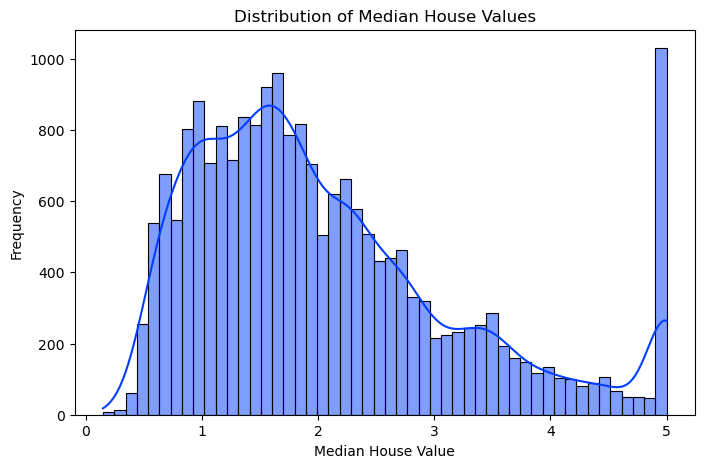

In [23]:
# distribution of target variable
plt.figure(figsize = (8,5))
sns.histplot(y,bins = 50, kde = True ,color=sns.color_palette("bright")[0])
plt.title('Distribution of Median House Values')
plt.xlabel('Median House Value')
plt.ylabel('Frequency')
plt.show()

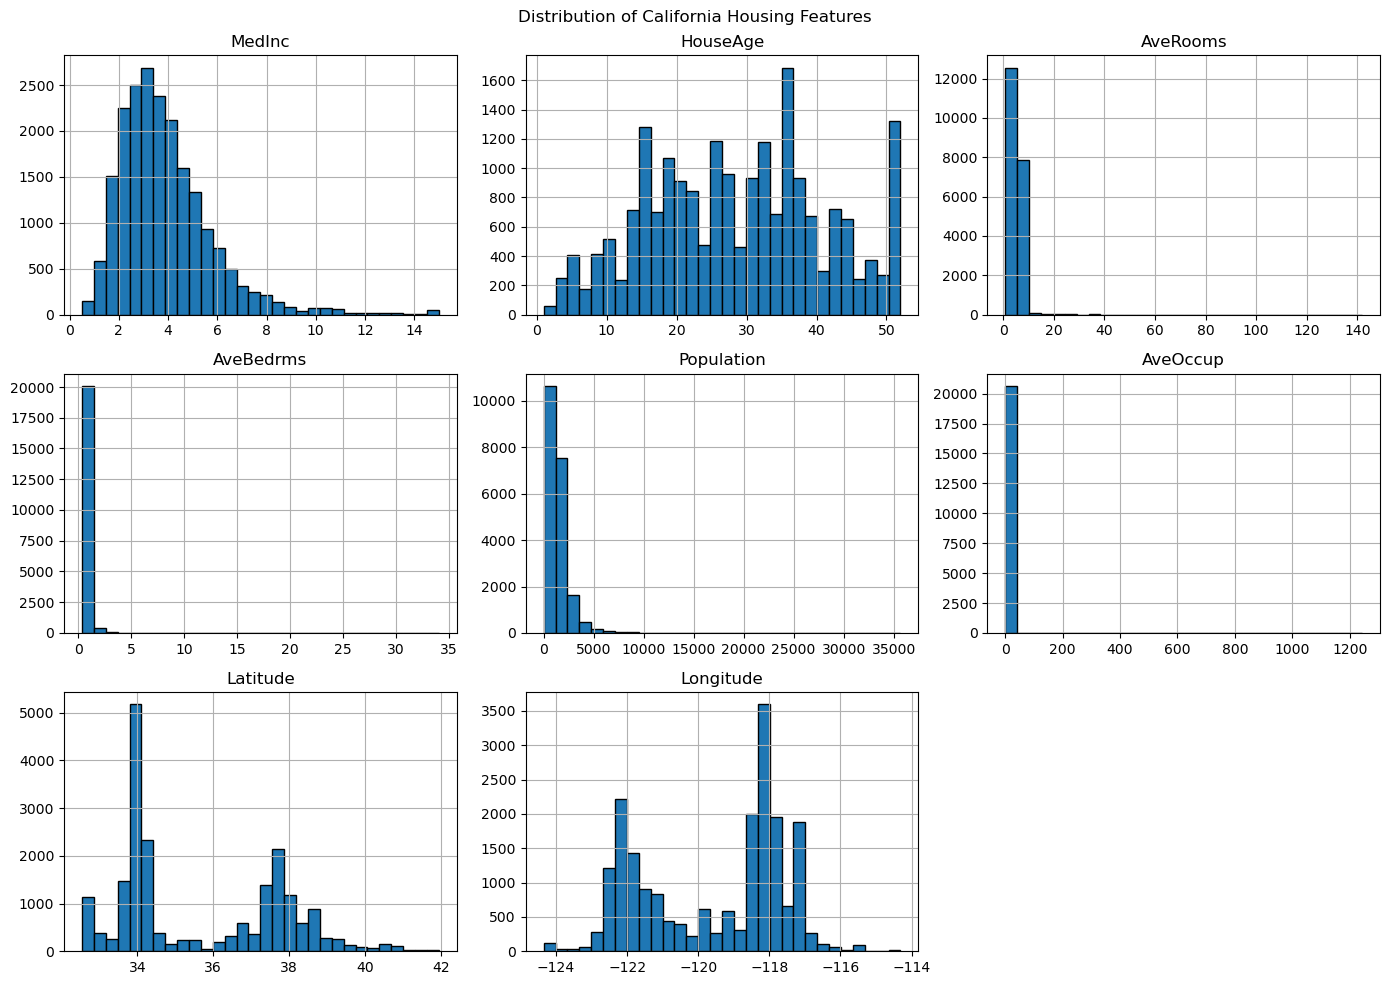

In [24]:
# distribution of numerical features
X.hist(figsize=(14, 10), bins=30, edgecolor='black')

plt.suptitle('Distribution of California Housing Features')
plt.tight_layout()
plt.show()

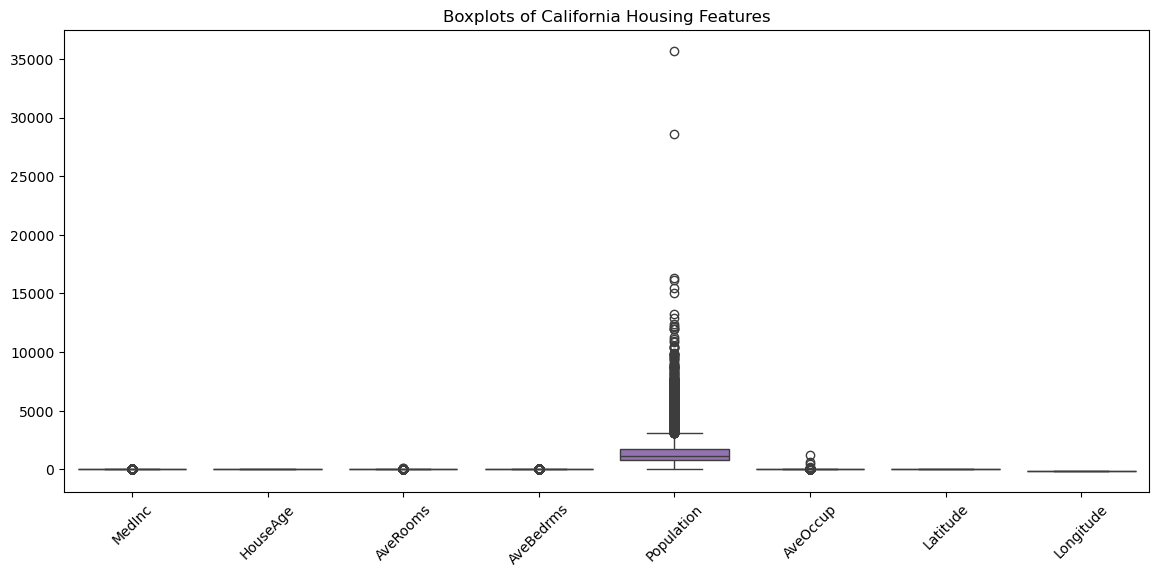

In [25]:
# outliers 
plt.figure(figsize=(14, 6))

sns.boxplot(data=X)

plt.title('Boxplots of California Housing Features')
plt.xticks(rotation=45)
plt.show()

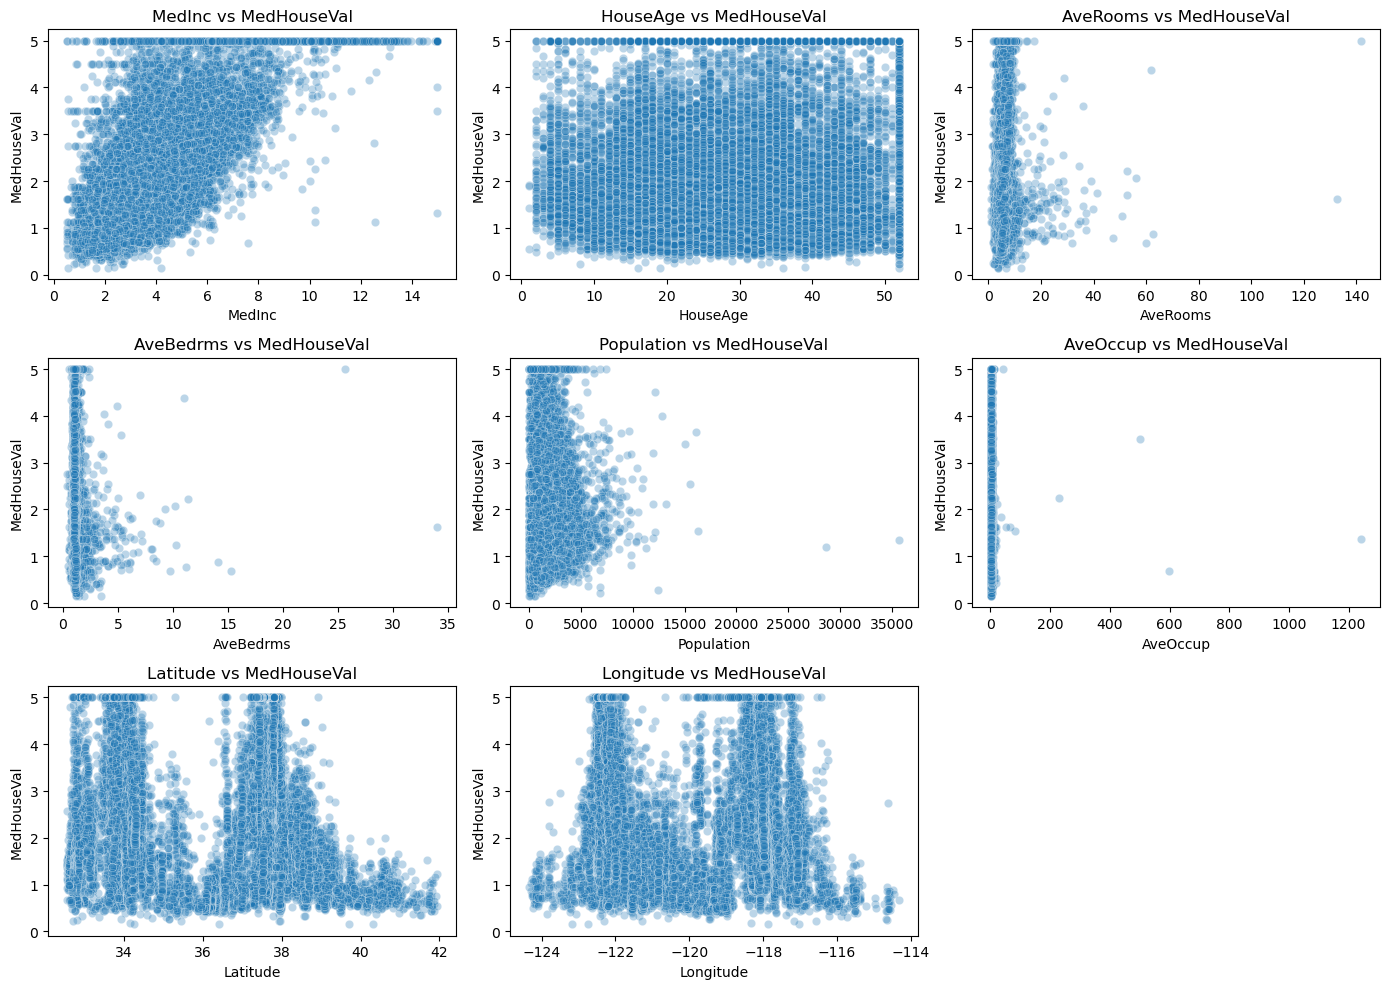

In [27]:
# feature rlship with target
plt.figure(figsize=(14, 10))

for i, column in enumerate(X.columns, 1):
    plt.subplot(3, 3, i)
    sns.scatterplot(x=X[column], y=y, alpha=0.3)
    plt.title(f'{column} vs MedHouseVal')
    plt.xlabel(column)
    plt.ylabel('MedHouseVal')

plt.tight_layout()
plt.show()

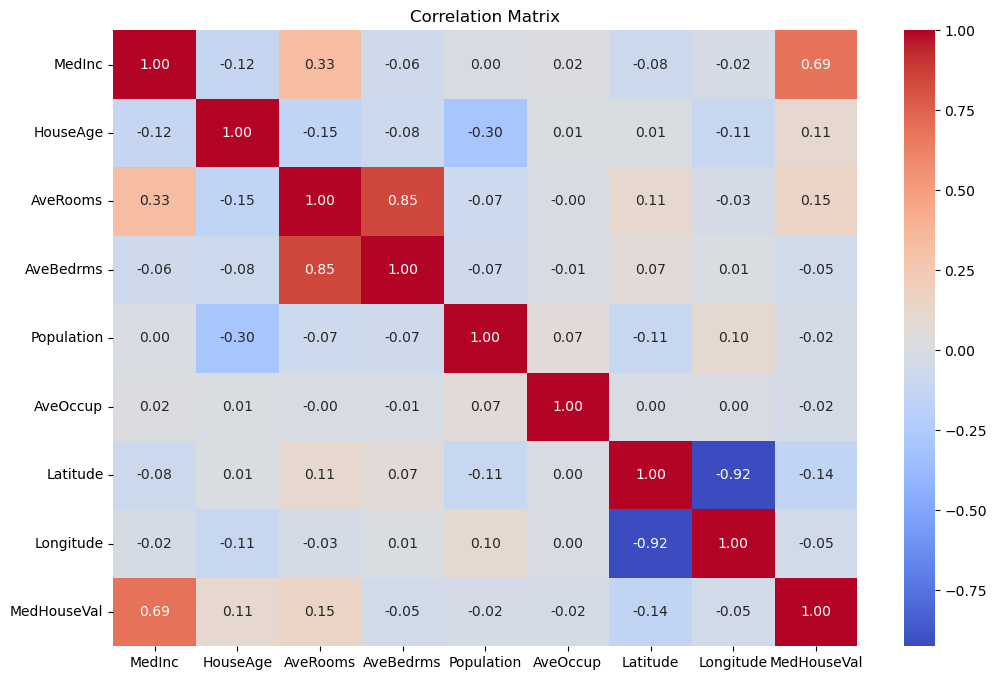

In [30]:
# correlation analysis
plt.figure(figsize = (12,8))
corr = df.corr()
sns.heatmap(corr,annot = True,cmap = 'coolwarm',fmt='.2f')
plt.title('Correlation Matrix')
plt.show()

####  EDA summary

- MedInc shows a strong positive correlation with MedHouseVal.
- Housing values generally increase as median income increases.
- Some features contain potential outliers.
- Features have different scales and distributions.
- Some relationships between features and the target may be nonlinear.

In [31]:
# preprocessing
# separate features  and target
X = df.drop(columns = 'MedHouseVal')
y = df['MedHouseVal']
print(X.shape)
y.shape

(20640, 8)


(20640,)

In [32]:
# split dataset
X_train,X_test,y_train,y_test = train_test_split(X,y,test_size = 0.2,random_state = 42)
print(X_train.shape)
X_test.shape

(16512, 8)


(4128, 8)

In [34]:
# Modelling
lr = LinearRegression()
lr.fit(X_train,y_train) # train model

,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,None
,positive,False


In [41]:
# predictions
y_train_pred = lr.predict(X_train)
y_test_pred = lr.predict(X_test)

In [37]:
# coefficients
coefficients = pd.DataFrame({
    'Feature': X.columns,
    'Coefficient': lr.coef_
}).sort_values(by='Coefficient', ascending=False)

coefficients

,Feature,Coefficient
3,AveBedrms,0.783145
0,MedInc,0.448675
1,HouseAge,0.009724
4,Population,-0.000002
5,AveOccup,-0.003526
2,AveRooms,-0.123323
6,Latitude,-0.419792
7,Longitude,-0.433708


In [39]:
# intercept
lr.intercept_

np.float64(-37.023277706064235)

In [42]:
# Evaluation
# Training metrics
train_mae = mean_absolute_error(y_train, y_train_pred)
train_mse = mean_squared_error(y_train, y_train_pred)
train_rmse = np.sqrt(train_mse)
train_r2 = r2_score(y_train, y_train_pred)
# Testing metrics
test_mae = mean_absolute_error(y_test, y_test_pred)
test_mse = mean_squared_error(y_test, y_test_pred)
test_rmse = np.sqrt(test_mse)
test_r2 = r2_score(y_test, y_test_pred)

results = pd.DataFrame({
    'Metric': ['MAE', 'MSE', 'RMSE', 'R²'],
    'Training': [train_mae, train_mse, train_rmse, train_r2],
    'Testing': [test_mae, test_mse, test_rmse, test_r2]
})

results

,Metric,Training,Testing
0,MAE,0.528628,0.533200
1,MSE,0.517933,0.555892
2,RMSE,0.719676,0.745581
3,R²,0.612551,0.575788


### Evaluation Observations
- The model achieved a testing R² score of approximately 0.576.
- Training and testing errors are relatively close, suggesting reasonable generalization.
- The model explains about 57.6% of the variation in median house values.
- The prediction errors indicate that there is room for improvement.

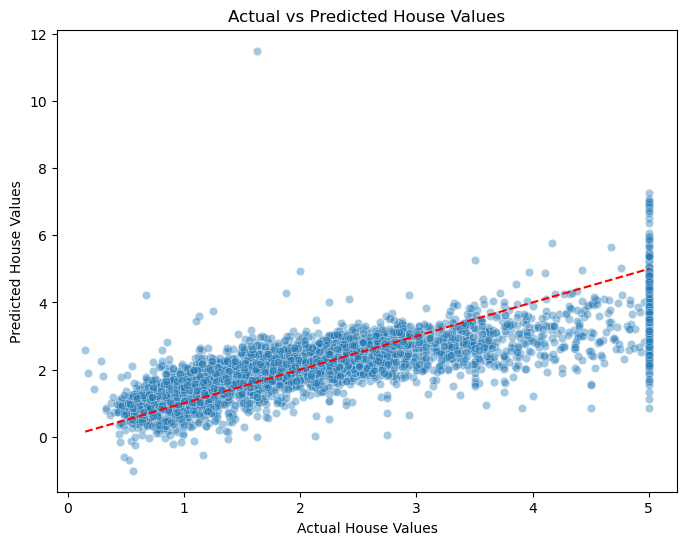

In [43]:
# Actual vs predicted
plt.figure(figsize=(8, 6))

sns.scatterplot(x=y_test, y=y_test_pred, alpha=0.4)

plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    color='red',
    linestyle='--'
)

plt.xlabel('Actual House Values')
plt.ylabel('Predicted House Values')
plt.title('Actual vs Predicted House Values')
plt.show()

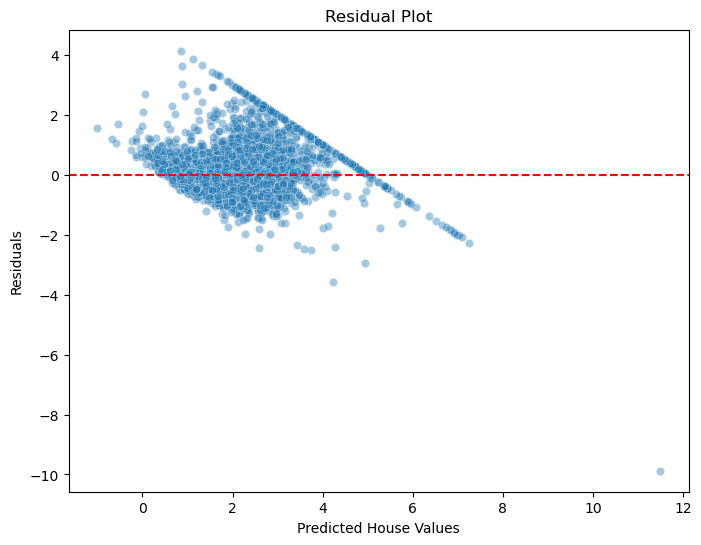

In [44]:
# Residual
residuals = y_test - y_test_pred

plt.figure(figsize=(8, 6))
sns.scatterplot(x=y_test_pred, y=residuals, alpha=0.4)

plt.axhline(y=0, color='red', linestyle='--')

plt.xlabel('Predicted House Values')
plt.ylabel('Residuals')
plt.title('Residual Plot')
plt.show()